# Section 8. Result Analysis and Visualization

section 7 결과 불러와서 최종 표, 그래프, 보고서용 해석 문장 정리하기

In [1]:
# ============================================================
# Section 8. Result Analysis and Visualization
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from dataclasses import dataclass

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 120)
pd.set_option("display.float_format", "{:,.6f}".format)

SEED = 42
np.random.seed(SEED)

In [2]:
# ============================================================
# 8-0. Project Directory Setting
# ============================================================

PROJECT_NAME = "ELS hege 5.19"
CURRENT_DIR = Path.cwd()


def find_project_dir(project_name=PROJECT_NAME):
    """
    Resolve the local project folder from the notebook folder, a subfolder,
    or the parent workspace folder.
    """
    current = Path.cwd().resolve()

    if current.name == project_name:
        return current

    for parent in current.parents:
        if parent.name == project_name:
            return parent

    for base in [current, *current.parents]:
        candidate = base / project_name
        if candidate.exists():
            return candidate.resolve()

    return current / project_name


PROJECT_DIR = find_project_dir()

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "output"
FIGURE_DIR = PROJECT_DIR / "figures"
CODE_DIR = PROJECT_DIR

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

KOSPI200_PATH = DATA_DIR / "kospi200_close_new.csv"

print("CURRENT_DIR:", CURRENT_DIR)
print("PROJECT_DIR:", PROJECT_DIR)
print("DATA_DIR:", DATA_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)
print("FIGURE_DIR:", FIGURE_DIR)
print("CODE_DIR:", CODE_DIR)
print("KOSPI200_PATH:", KOSPI200_PATH)
print("Data file exists:", KOSPI200_PATH.exists())


CURRENT_DIR: c:\Users\Yeonsoo\Desktop\project\ELS hege 5.19
PROJECT_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19
DATA_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\data
OUTPUT_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output
FIGURE_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\figures
CODE_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19
KOSPI200_PATH: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\data\kospi200_close_new.csv
Data file exists: True


In [3]:
# ============================================================
# 8-1. Load Final Results
# ============================================================

terminal_summary = pd.read_csv(
    OUTPUT_DIR / "terminal_balance_summary.csv"
)

rank_by_mean = pd.read_csv(
    OUTPUT_DIR / "rank_by_mean_terminal_balance.csv"
)

rank_by_p05 = pd.read_csv(
    OUTPUT_DIR / "rank_by_p05_terminal_balance.csv"
)

rank_by_score = pd.read_csv(
    OUTPUT_DIR / "rank_by_risk_adjusted_score.csv"
)

best_result_df = pd.read_csv(
    OUTPUT_DIR / "best_experiment_pathwise_result.csv"
)

best_by_payoff_type = pd.read_csv(
    OUTPUT_DIR / "best_experiment_by_payoff_type.csv"
)

best_by_principal_ratio = pd.read_csv(
    OUTPUT_DIR / "best_by_principal_book_ratio.csv"
)

payoff_df = pd.read_csv(
    OUTPUT_DIR / "els_payoff_result.csv"
)

terminal_balance_matrix = np.load(
    OUTPUT_DIR / "terminal_balance_matrix.npy"
)

principal_terminal_matrix = np.load(
    OUTPUT_DIR / "principal_terminal_matrix.npy"
)

static_terminal_account_matrix = np.load(
    OUTPUT_DIR / "static_terminal_account_matrix.npy"
)

dynamic_terminal_account_matrix = np.load(
    OUTPUT_DIR / "dynamic_terminal_account_matrix.npy"
)

print("terminal_summary shape:", terminal_summary.shape)
print("terminal_balance_matrix shape:", terminal_balance_matrix.shape)

display(terminal_summary.head())
display(best_result_df.head())

terminal_summary shape: (33, 27)
terminal_balance_matrix shape: (33, 10000)


,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,principal_book_amount,hedge_book_amount,static_budget,dynamic_budget,mean_terminal_balance,std_terminal_balance,min_terminal_balance,p01_terminal_balance,p05_terminal_balance,p10_terminal_balance,p50_terminal_balance,p90_terminal_balance,p95_terminal_balance,max_terminal_balance,prob_negative_balance,prob_below_initial_notional,mean_principal_terminal,mean_static_terminal_account,mean_dynamic_terminal_account,mean_static_pnl,mean_dynamic_pnl,risk_adjusted_score
0,0,0.300000,0.700000,0.000000,1.000000,"3,000,000,000.000000","7,000,000,000.000000",0.000000,"7,000,000,000.000000","-632,615,986.757715","1,167,812,459.561455","-7,757,417,939.755374","-3,918,956,510.408398","-2,227,219,144.914641","-1,590,381,894.610578","-628,592,243.485955","-83,916,002.828750","450,750,982.258473","9,244,996,160.402617",0.911700,1.000000,"-8,093,430,168.912080",0.000000,"7,460,814,182.154364",0.000000,"12,076,481.201045","-1,216,522,216.538443"
1,1,0.300000,0.700000,0.100000,0.900000,"3,000,000,000.000000","7,000,000,000.000000","700,000,000.000000","6,300,000,000.000000","-612,426,583.600083","1,118,523,036.629080","-7,141,617,038.626152","-3,638,714,385.414131","-2,215,185,397.519275","-1,556,023,751.125916","-590,374,950.382275","-109,606,339.856896","371,286,538.490875","8,751,555,651.516039",0.914800,1.000000,"-8,093,430,168.912080","766,270,821.373068","6,714,732,763.938928","603,412.788824","10,868,833.080942","-1,171,688,101.914622"
2,2,0.300000,0.700000,0.200000,0.800000,"3,000,000,000.000000","7,000,000,000.000000","1,400,000,000.000000","5,600,000,000.000000","-592,237,180.442451","1,072,753,249.950742","-6,525,816,137.496934","-3,266,916,924.521206","-2,196,265,491.917036","-1,513,568,220.836553","-551,289,679.817546","-127,764,466.053344","297,915,032.910644","8,258,115,142.629467",0.918900,1.000000,"-8,093,430,168.912080","1,532,541,642.746136","5,968,651,345.723491","1,206,825.577647","9,661,184.960836","-1,128,613,805.417822"
3,3,0.300000,0.700000,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000","2,100,000,000.000000","4,900,000,000.000000","-572,047,777.284820","1,030,971,966.707533","-5,942,801,324.481939","-3,010,274,302.254835","-2,176,185,763.102603","-1,467,107,862.349844","-513,621,570.476408","-144,476,893.825382","218,516,390.694873","7,764,674,633.742889",0.924200,1.000000,"-8,093,430,168.912080","2,298,812,464.119205","5,222,569,927.508055","1,810,238.366471","8,453,536.840731","-1,087,533,760.638586"
4,4,0.300000,0.700000,0.400000,0.600000,"3,000,000,000.000000","7,000,000,000.000000","2,800,000,000.000000","4,200,000,000.000000","-551,858,374.127187","993,682,427.157035","-5,568,687,113.443436","-3,105,207,663.241334","-2,149,209,175.752726","-1,407,128,911.424678","-476,949,410.947356","-167,959,483.952105","149,322,243.556034","7,271,234,124.856305",0.929400,1.000000,"-8,093,430,168.912080","3,065,083,285.492273","4,476,488,509.292619","2,413,651.155294","7,245,888.720628","-1,048,699,587.705705"


,path_id,payoff_type,autocall_no,knock_in_occurred,issuer_cash_outflow,principal_terminal,static_terminal_account,dynamic_terminal_account,terminal_balance
0,0,autocall_1,1,False,"10,485,000,000.000000","-8,018,755,536.765878","7,510,172,038.021171",0.000000,"-508,583,498.744707"
1,1,autocall_1,1,False,"10,485,000,000.000000","-8,018,755,536.765878","7,988,208,877.325492",0.000000,"-30,546,659.440386"
2,2,autocall_1,1,False,"10,485,000,000.000000","-8,018,755,536.765878","7,844,755,164.071037",0.000000,"-174,000,372.694840"
3,3,autocall_1,1,False,"10,485,000,000.000000","-8,018,755,536.765878","7,486,272,019.382648",0.000000,"-532,483,517.383229"
4,4,autocall_1,1,False,"10,485,000,000.000000","-8,018,755,536.765878","7,543,212,053.668926",0.000000,"-475,543,483.096951"


In [4]:
# ============================================================
# 8-2. Ranking Tables
# ============================================================

ranking_cols = [
    "experiment_id",
    "principal_book_ratio",
    "hedge_book_ratio",
    "static_ratio",
    "dynamic_ratio",
    "mean_terminal_balance",
    "std_terminal_balance",
    "p05_terminal_balance",
    "p50_terminal_balance",
    "prob_negative_balance",
    "prob_below_initial_notional",
    "risk_adjusted_score",
]

top_by_mean = rank_by_mean[ranking_cols].head(10).copy()
top_by_p05 = rank_by_p05[ranking_cols].head(10).copy()
top_by_score = rank_by_score[ranking_cols].head(10).copy()

# 억원 단위 컬럼 추가
money_cols = [
    "mean_terminal_balance",
    "std_terminal_balance",
    "p05_terminal_balance",
    "p50_terminal_balance",
    "risk_adjusted_score",
]

for df in [top_by_mean, top_by_p05, top_by_score]:
    for col in money_cols:
        df[col + "_100m"] = df[col] / 1e8

print("Top 10 by Mean Terminal Balance")
display(top_by_mean)

print("Top 10 by 5% Terminal Balance")
display(top_by_p05)

print("Top 10 by Risk-adjusted Score")
display(top_by_score)

Top 10 by Mean Terminal Balance


,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,mean_terminal_balance,std_terminal_balance,p05_terminal_balance,p50_terminal_balance,prob_negative_balance,prob_below_initial_notional,risk_adjusted_score,mean_terminal_balance_100m,std_terminal_balance_100m,p05_terminal_balance_100m,p50_terminal_balance_100m,risk_adjusted_score_100m
0,10,0.300000,0.700000,1.000000,0.000000,"-430,721,955.181397","891,498,892.568358","-1,599,408,928.463153","-287,531,851.232797",0.986700,1.000000,"-876,471,401.465576",-4.307220,8.914989,-15.994089,-2.875319,-8.764714
1,21,0.500000,0.500000,1.000000,0.000000,"-432,225,666.474645","892,661,418.399981","-1,692,232,657.797280","-306,109,693.306799",0.987000,1.000000,"-878,556,375.674636",-4.322257,8.926614,-16.922327,-3.061097,-8.785564
2,32,0.700000,0.300000,1.000000,0.000000,"-434,037,833.112641","919,451,358.927305","-1,804,097,259.911256","-328,498,396.353452",0.987000,1.000000,"-893,763,512.576293",-4.340378,9.194514,-18.040973,-3.284984,-8.937635
3,31,0.700000,0.300000,0.900000,0.100000,"-442,566,421.494655","926,723,122.429067","-1,836,131,446.200453","-341,413,122.969931",0.987000,1.000000,"-905,927,982.709189",-4.425664,9.267231,-18.361314,-3.414131,-9.059280
4,20,0.500000,0.500000,0.900000,0.100000,"-446,548,555.032833","898,571,046.123686","-1,741,415,503.427895","-327,042,203.245620",0.986600,1.000000,"-895,834,078.094676",-4.465486,8.985710,-17.414155,-3.270422,-8.958341
5,9,0.300000,0.700000,0.900000,0.100000,"-450,911,358.339028","892,121,769.303297","-1,663,880,839.357902","-315,658,935.787122",0.984000,1.000000,"-896,972,242.990677",-4.509114,8.921218,-16.638808,-3.156589,-8.969722
6,30,0.700000,0.300000,0.800000,0.200000,"-451,095,009.876670","935,837,166.584620","-1,868,207,951.613168","-355,327,468.323282",0.986300,1.000000,"-919,013,593.168980",-4.510950,9.358372,-18.682080,-3.553275,-9.190136
7,29,0.700000,0.300000,0.700000,0.300000,"-459,623,598.258684","946,740,287.292465","-1,899,461,020.906871","-373,053,644.500874",0.980300,1.000000,"-932,993,741.904917",-4.596236,9.467403,-18.994610,-3.730536,-9.329937
8,19,0.500000,0.500000,0.800000,0.200000,"-460,871,443.591021","908,725,201.327344","-1,791,006,102.776204","-346,640,711.939888",0.981100,1.000000,"-915,234,044.254693",-4.608714,9.087252,-17.910061,-3.466407,-9.152340
9,28,0.700000,0.300000,0.600000,0.400000,"-468,152,186.640699","959,371,488.688896","-1,931,660,601.317338","-391,551,135.428505",0.970200,1.000000,"-947,837,930.985147",-4.681522,9.593715,-19.316606,-3.915511,-9.478379


Top 10 by 5% Terminal Balance


,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,mean_terminal_balance,std_terminal_balance,p05_terminal_balance,p50_terminal_balance,prob_negative_balance,prob_below_initial_notional,risk_adjusted_score,mean_terminal_balance_100m,std_terminal_balance_100m,p05_terminal_balance_100m,p50_terminal_balance_100m,risk_adjusted_score_100m
0,10,0.300000,0.700000,1.000000,0.000000,"-430,721,955.181397","891,498,892.568358","-1,599,408,928.463153","-287,531,851.232797",0.986700,1.000000,"-876,471,401.465576",-4.307220,8.914989,-15.994089,-2.875319,-8.764714
1,9,0.300000,0.700000,0.900000,0.100000,"-450,911,358.339028","892,121,769.303297","-1,663,880,839.357902","-315,658,935.787122",0.984000,1.000000,"-896,972,242.990677",-4.509114,8.921218,-16.638808,-3.156589,-8.969722
2,21,0.500000,0.500000,1.000000,0.000000,"-432,225,666.474645","892,661,418.399981","-1,692,232,657.797280","-306,109,693.306799",0.987000,1.000000,"-878,556,375.674636",-4.322257,8.926614,-16.922327,-3.061097,-8.785564
3,8,0.300000,0.700000,0.800000,0.200000,"-471,100,761.496660","899,661,122.937998","-1,728,632,570.434265","-341,428,705.009401",0.973900,1.000000,"-920,931,322.965660",-4.711008,8.996611,-17.286326,-3.414287,-9.209313
4,20,0.500000,0.500000,0.900000,0.100000,"-446,548,555.032833","898,571,046.123686","-1,741,415,503.427895","-327,042,203.245620",0.986600,1.000000,"-895,834,078.094676",-4.465486,8.985710,-17.414155,-3.270422,-8.958341
5,19,0.500000,0.500000,0.800000,0.200000,"-460,871,443.591021","908,725,201.327344","-1,791,006,102.776204","-346,640,711.939888",0.981100,1.000000,"-915,234,044.254693",-4.608714,9.087252,-17.910061,-3.466407,-9.152340
6,7,0.300000,0.700000,0.700000,0.300000,"-491,290,164.654293","913,945,802.569415","-1,796,446,061.448593","-370,879,860.117585",0.961900,1.000000,"-948,263,065.939000",-4.912902,9.139458,-17.964461,-3.708799,-9.482631
7,32,0.700000,0.300000,1.000000,0.000000,"-434,037,833.112641","919,451,358.927305","-1,804,097,259.911256","-328,498,396.353452",0.987000,1.000000,"-893,763,512.576293",-4.340378,9.194514,-18.040973,-3.284984,-8.937635
8,31,0.700000,0.300000,0.900000,0.100000,"-442,566,421.494655","926,723,122.429067","-1,836,131,446.200453","-341,413,122.969931",0.987000,1.000000,"-905,927,982.709189",-4.425664,9.267231,-18.361314,-3.414131,-9.059280
9,18,0.500000,0.500000,0.700000,0.300000,"-475,194,332.149208","922,983,806.838822","-1,840,392,825.265666","-370,324,042.699626",0.969100,1.000000,"-936,686,235.568619",-4.751943,9.229838,-18.403928,-3.703240,-9.366862


Top 10 by Risk-adjusted Score


,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,mean_terminal_balance,std_terminal_balance,p05_terminal_balance,p50_terminal_balance,prob_negative_balance,prob_below_initial_notional,risk_adjusted_score,mean_terminal_balance_100m,std_terminal_balance_100m,p05_terminal_balance_100m,p50_terminal_balance_100m,risk_adjusted_score_100m
0,10,0.300000,0.700000,1.000000,0.000000,"-430,721,955.181397","891,498,892.568358","-1,599,408,928.463153","-287,531,851.232797",0.986700,1.000000,"-876,471,401.465576",-4.307220,8.914989,-15.994089,-2.875319,-8.764714
1,21,0.500000,0.500000,1.000000,0.000000,"-432,225,666.474645","892,661,418.399981","-1,692,232,657.797280","-306,109,693.306799",0.987000,1.000000,"-878,556,375.674636",-4.322257,8.926614,-16.922327,-3.061097,-8.785564
2,32,0.700000,0.300000,1.000000,0.000000,"-434,037,833.112641","919,451,358.927305","-1,804,097,259.911256","-328,498,396.353452",0.987000,1.000000,"-893,763,512.576293",-4.340378,9.194514,-18.040973,-3.284984,-8.937635
3,20,0.500000,0.500000,0.900000,0.100000,"-446,548,555.032833","898,571,046.123686","-1,741,415,503.427895","-327,042,203.245620",0.986600,1.000000,"-895,834,078.094676",-4.465486,8.985710,-17.414155,-3.270422,-8.958341
4,9,0.300000,0.700000,0.900000,0.100000,"-450,911,358.339028","892,121,769.303297","-1,663,880,839.357902","-315,658,935.787122",0.984000,1.000000,"-896,972,242.990677",-4.509114,8.921218,-16.638808,-3.156589,-8.969722
5,31,0.700000,0.300000,0.900000,0.100000,"-442,566,421.494655","926,723,122.429067","-1,836,131,446.200453","-341,413,122.969931",0.987000,1.000000,"-905,927,982.709189",-4.425664,9.267231,-18.361314,-3.414131,-9.059280
6,19,0.500000,0.500000,0.800000,0.200000,"-460,871,443.591021","908,725,201.327344","-1,791,006,102.776204","-346,640,711.939888",0.981100,1.000000,"-915,234,044.254693",-4.608714,9.087252,-17.910061,-3.466407,-9.152340
7,30,0.700000,0.300000,0.800000,0.200000,"-451,095,009.876670","935,837,166.584620","-1,868,207,951.613168","-355,327,468.323282",0.986300,1.000000,"-919,013,593.168980",-4.510950,9.358372,-18.682080,-3.553275,-9.190136
8,8,0.300000,0.700000,0.800000,0.200000,"-471,100,761.496660","899,661,122.937998","-1,728,632,570.434265","-341,428,705.009401",0.973900,1.000000,"-920,931,322.965660",-4.711008,8.996611,-17.286326,-3.414287,-9.209313
9,29,0.700000,0.300000,0.700000,0.300000,"-459,623,598.258684","946,740,287.292465","-1,899,461,020.906871","-373,053,644.500874",0.980300,1.000000,"-932,993,741.904917",-4.596236,9.467403,-18.994610,-3.730536,-9.329937


기본 추천 조함은 section 7에서 사용한 기준과 동일하게 5% terminal balance가 가장 높은 조합으로 봅니다 (상당히 자의적임 다시 해석해야함)

In [5]:
# ============================================================
# 8-3. Recommended Combination
# ============================================================

recommended = rank_by_p05.iloc[0].copy()
recommended_id = int(recommended["experiment_id"])

recommended_table = pd.DataFrame([recommended])
recommended_table_display = recommended_table[ranking_cols].copy()

for col in money_cols:
    recommended_table_display[col + "_100m"] = recommended_table_display[col] / 1e8

print("Recommended experiment ID:", recommended_id)
display(recommended_table_display)

Recommended experiment ID: 10


,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,mean_terminal_balance,std_terminal_balance,p05_terminal_balance,p50_terminal_balance,prob_negative_balance,prob_below_initial_notional,risk_adjusted_score,mean_terminal_balance_100m,std_terminal_balance_100m,p05_terminal_balance_100m,p50_terminal_balance_100m,risk_adjusted_score_100m
0,10.000000,0.300000,0.700000,1.000000,0.000000,"-430,721,955.181397","891,498,892.568358","-1,599,408,928.463153","-287,531,851.232797",0.986700,1.000000,"-876,471,401.465576",-4.307220,8.914989,-15.994089,-2.875319,-8.764714


In [6]:
# ============================================================
# 8-4. Best Combination by Principal Book Ratio
# ============================================================

best_by_principal_display = best_by_principal_ratio[ranking_cols].copy()

for col in money_cols:
    best_by_principal_display[col + "_100m"] = best_by_principal_display[col] / 1e8

best_by_principal_display

,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,mean_terminal_balance,std_terminal_balance,p05_terminal_balance,p50_terminal_balance,prob_negative_balance,prob_below_initial_notional,risk_adjusted_score,mean_terminal_balance_100m,std_terminal_balance_100m,p05_terminal_balance_100m,p50_terminal_balance_100m,risk_adjusted_score_100m
0,10,0.300000,0.700000,1.000000,0.000000,"-430,721,955.181397","891,498,892.568358","-1,599,408,928.463153","-287,531,851.232797",0.986700,1.000000,"-876,471,401.465576",-4.307220,8.914989,-15.994089,-2.875319,-8.764714
1,21,0.500000,0.500000,1.000000,0.000000,"-432,225,666.474645","892,661,418.399981","-1,692,232,657.797280","-306,109,693.306799",0.987000,1.000000,"-878,556,375.674636",-4.322257,8.926614,-16.922327,-3.061097,-8.785564
2,32,0.700000,0.300000,1.000000,0.000000,"-434,037,833.112641","919,451,358.927305","-1,804,097,259.911256","-328,498,396.353452",0.987000,1.000000,"-893,763,512.576293",-4.340378,9.194514,-18.040973,-3.284984,-8.937635


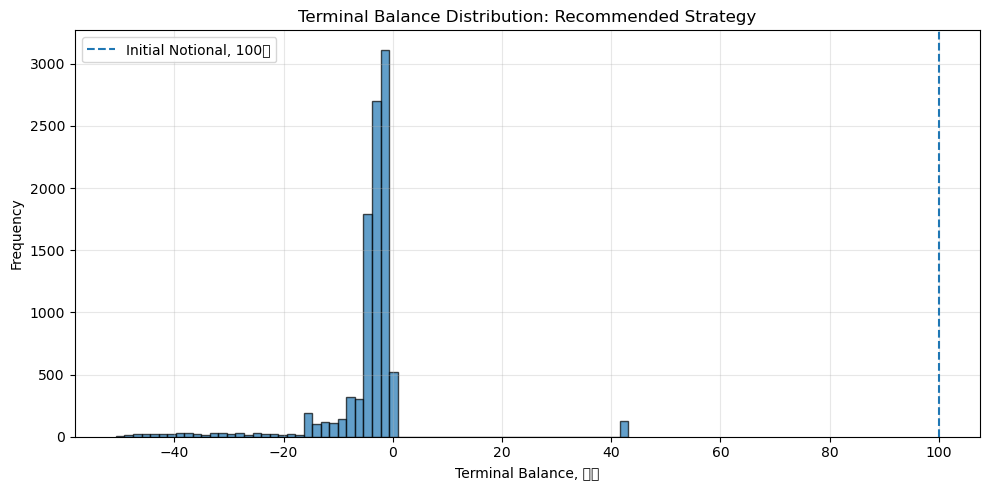

Saved figure to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\figures\section8_terminal_balance_distribution.png


In [7]:
# ============================================================
# 8-5. Terminal Balance Distribution
# ============================================================

best_terminal_balance = terminal_balance_matrix[recommended_id, :]

plt.figure(figsize=(10, 5))
plt.hist(best_terminal_balance / 1e8, bins=60, edgecolor="black", alpha=0.7)
plt.axvline(100, linestyle="--", label="Initial Notional, 100억")
plt.title("Terminal Balance Distribution: Recommended Strategy")
plt.xlabel("Terminal Balance, 억원")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

fig_path = FIGURE_DIR / "section8_terminal_balance_distribution.png"
plt.savefig(fig_path, dpi=300)
plt.show()

print("Saved figure to:", fig_path)

In [8]:
# ============================================================
# 8-6. Component Distribution
# ============================================================

component_df = pd.DataFrame({
    "principal_terminal": principal_terminal_matrix[recommended_id, :],
    "static_terminal_account": static_terminal_account_matrix[recommended_id, :],
    "dynamic_terminal_account": dynamic_terminal_account_matrix[recommended_id, :],
    "terminal_balance": terminal_balance_matrix[recommended_id, :],
})

component_summary = component_df.describe().T
component_summary["mean_100m"] = component_summary["mean"] / 1e8
component_summary["std_100m"] = component_summary["std"] / 1e8
component_summary["min_100m"] = component_summary["min"] / 1e8
component_summary["p05_100m"] = component_df.quantile(0.05) / 1e8
component_summary["p50_100m"] = component_df.quantile(0.50) / 1e8
component_summary["p95_100m"] = component_df.quantile(0.95) / 1e8

component_summary

,count,mean,std,min,25%,50%,75%,max,mean_100m,std_100m,min_100m,p05_100m,p50_100m,p95_100m
principal_terminal,"10,000.000000","-8,093,430,168.912080","1,006,270,138.966248","-9,628,568,248.924665","-8,018,755,536.765878","-8,018,755,536.765878","-8,018,755,536.765878","1,499,403,038.907814",-80.934302,10.062701,-96.285682,-96.285682,-80.187555,-80.187555
static_terminal_account,"10,000.000000","7,662,708,213.730681","528,221,269.251686","2,811,188,032.629032","7,645,367,039.062248","7,770,135,522.572949","7,869,717,968.869704","8,029,159,320.461513",76.627082,5.282213,28.111880,72.325151,77.701355,79.728507
dynamic_terminal_account,"10,000.000000",0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
terminal_balance,"10,000.000000","-430,721,955.181397","891,498,892.568359","-5,068,909,502.580158","-464,970,785.672867","-287,531,851.232797","-163,929,530.550688","4,310,591,071.536848",-4.307220,8.914989,-50.689095,-15.994089,-2.875319,-0.548945


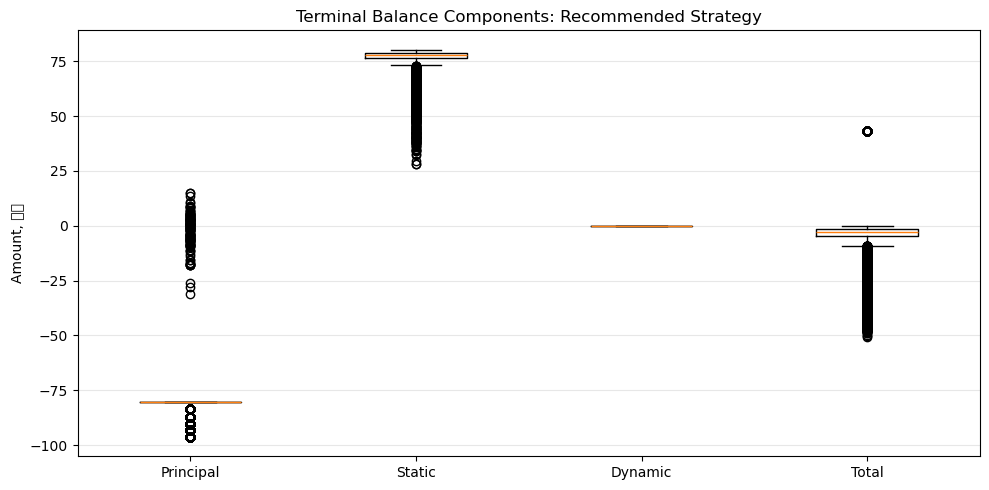

Saved figure to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\figures\section8_component_boxplot.png


In [9]:
# ============================================================
# 8-6-1. Component Boxplot
# ============================================================

plt.figure(figsize=(10, 5))
plt.boxplot(
    [
        component_df["principal_terminal"] / 1e8,
        component_df["static_terminal_account"] / 1e8,
        component_df["dynamic_terminal_account"] / 1e8,
        component_df["terminal_balance"] / 1e8,
    ],
    labels=[
        "Principal",
        "Static",
        "Dynamic",
        "Total",
    ]
)

plt.title("Terminal Balance Components: Recommended Strategy")
plt.ylabel("Amount, 억원")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()

fig_path = FIGURE_DIR / "section8_component_boxplot.png"
plt.savefig(fig_path, dpi=300)
plt.show()

print("Saved figure to:", fig_path)

In [10]:
recommended_table_display[[
    "principal_book_ratio",
    "hedge_book_ratio",
    "static_ratio",
    "dynamic_ratio",
    "mean_terminal_balance_100m",
    "p05_terminal_balance_100m"
]]

,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,mean_terminal_balance_100m,p05_terminal_balance_100m
0,0.300000,0.700000,1.000000,0.000000,-4.307220,-15.994089


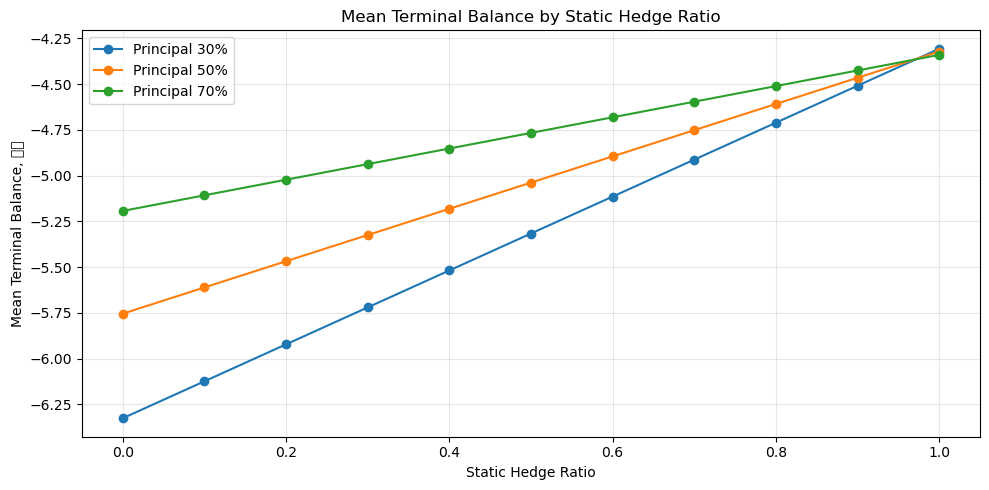

Saved figure to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\figures\section8_mean_balance_by_static_ratio.png


In [11]:
# ============================================================
# 8-7. Static Ratio Comparison
# ============================================================

plt.figure(figsize=(10, 5))

for principal_ratio in sorted(terminal_summary["principal_book_ratio"].unique()):
    temp = terminal_summary[
        terminal_summary["principal_book_ratio"] == principal_ratio
    ].sort_values("static_ratio")
    
    plt.plot(
        temp["static_ratio"],
        temp["mean_terminal_balance"] / 1e8,
        marker="o",
        label=f"Principal {principal_ratio:.0%}"
    )

plt.title("Mean Terminal Balance by Static Hedge Ratio")
plt.xlabel("Static Hedge Ratio")
plt.ylabel("Mean Terminal Balance, 억원")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

fig_path = FIGURE_DIR / "section8_mean_balance_by_static_ratio.png"
plt.savefig(fig_path, dpi=300)
plt.show()

print("Saved figure to:", fig_path)

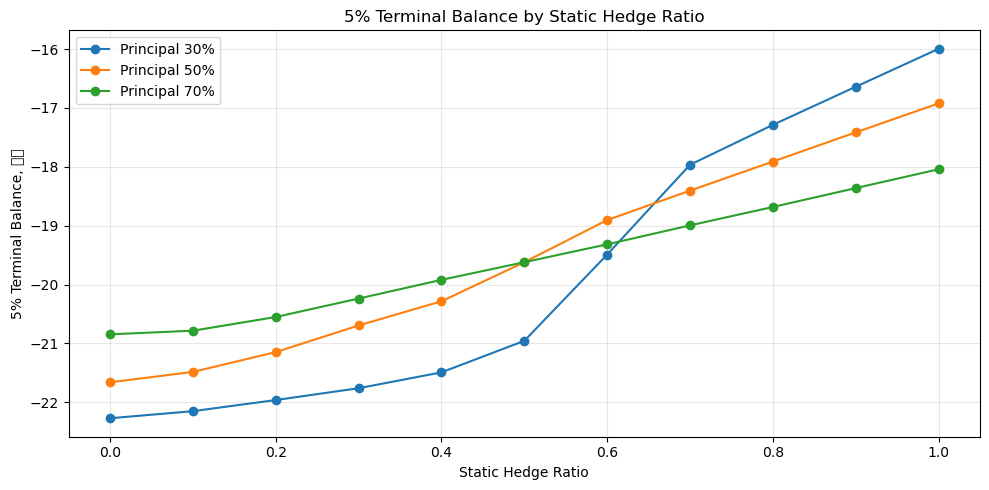

Saved figure to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\figures\section8_p05_balance_by_static_ratio.png


In [12]:
# ============================================================
# 8-7-1. 5% Terminal Balance by Static Ratio
# ============================================================

plt.figure(figsize=(10, 5))

for principal_ratio in sorted(terminal_summary["principal_book_ratio"].unique()):
    temp = terminal_summary[
        terminal_summary["principal_book_ratio"] == principal_ratio
    ].sort_values("static_ratio")
    
    plt.plot(
        temp["static_ratio"],
        temp["p05_terminal_balance"] / 1e8,
        marker="o",
        label=f"Principal {principal_ratio:.0%}"
    )

plt.title("5% Terminal Balance by Static Hedge Ratio")
plt.xlabel("Static Hedge Ratio")
plt.ylabel("5% Terminal Balance, 억원")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

fig_path = FIGURE_DIR / "section8_p05_balance_by_static_ratio.png"
plt.savefig(fig_path, dpi=300)
plt.show()

print("Saved figure to:", fig_path)

In [13]:
# ============================================================
# 8-8. Heatmap Function
# ============================================================

def plot_heatmap_from_summary(summary_df, value_col, title, save_name):
    pivot_df = summary_df.pivot_table(
        index="principal_book_ratio",
        columns="static_ratio",
        values=value_col
    )
    
    data = pivot_df.values / 1e8
    
    plt.figure(figsize=(12, 5))
    plt.imshow(data, aspect="auto")
    plt.colorbar(label="억원")
    
    plt.xticks(
        ticks=np.arange(len(pivot_df.columns)),
        labels=[f"{x:.1f}" for x in pivot_df.columns]
    )
    
    plt.yticks(
        ticks=np.arange(len(pivot_df.index)),
        labels=[f"{x:.1f}" for x in pivot_df.index]
    )
    
    plt.xlabel("Static Hedge Ratio")
    plt.ylabel("Principal Book Ratio")
    plt.title(title)
    
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            plt.text(
                j,
                i,
                f"{data[i, j]:.1f}",
                ha="center",
                va="center",
                fontsize=8
            )
    
    plt.tight_layout()
    
    fig_path = FIGURE_DIR / save_name
    plt.savefig(fig_path, dpi=300)
    plt.show()
    
    print("Saved figure to:", fig_path)
    
    return pivot_df

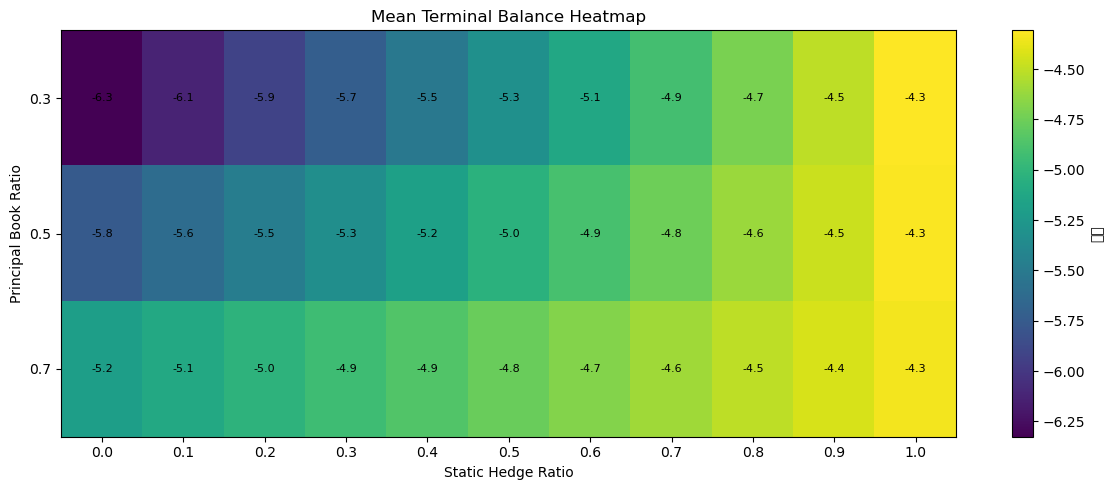

Saved figure to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\figures\section8_heatmap_mean_terminal_balance.png


In [14]:
pivot_mean = plot_heatmap_from_summary(
    terminal_summary,
    value_col="mean_terminal_balance",
    title="Mean Terminal Balance Heatmap",
    save_name="section8_heatmap_mean_terminal_balance.png"
)

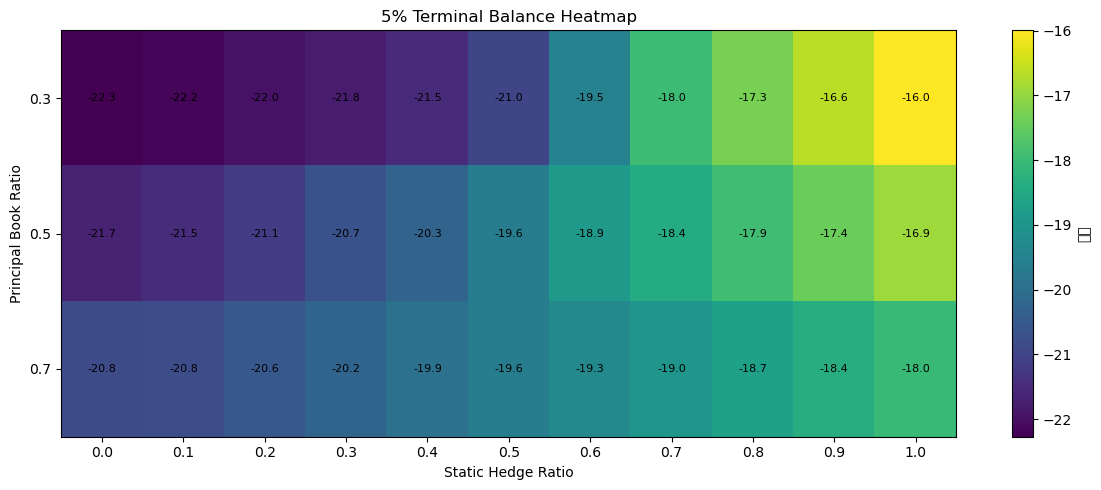

Saved figure to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\figures\section8_heatmap_p05_terminal_balance.png


In [15]:
pivot_p05 = plot_heatmap_from_summary(
    terminal_summary,
    value_col="p05_terminal_balance",
    title="5% Terminal Balance Heatmap",
    save_name="section8_heatmap_p05_terminal_balance.png"
)

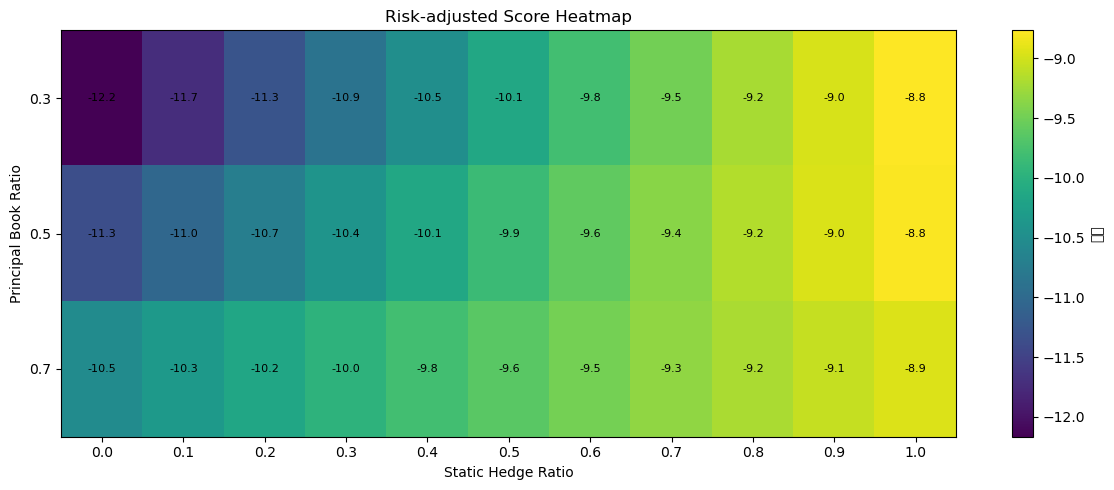

Saved figure to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\figures\section8_heatmap_risk_adjusted_score.png


In [16]:
pivot_score = plot_heatmap_from_summary(
    terminal_summary,
    value_col="risk_adjusted_score",
    title="Risk-adjusted Score Heatmap",
    save_name="section8_heatmap_risk_adjusted_score.png"
)

In [17]:
# ============================================================
# 8-9. Performance by Payoff Type
# ============================================================

best_by_payoff_type_display = best_by_payoff_type.copy()

payoff_money_cols = [
    "mean_terminal_balance",
    "min_terminal_balance",
    "p05_terminal_balance",
    "p50_terminal_balance",
    "mean_issuer_cash_outflow",
    "mean_principal_terminal",
    "mean_static_terminal_account",
    "mean_dynamic_terminal_account",
]

for col in payoff_money_cols:
    best_by_payoff_type_display[col + "_100m"] = best_by_payoff_type_display[col] / 1e8

best_by_payoff_type_display

,payoff_type,count,mean_terminal_balance,min_terminal_balance,p05_terminal_balance,p50_terminal_balance,mean_issuer_cash_outflow,mean_principal_terminal,mean_static_terminal_account,mean_dynamic_terminal_account,probability,mean_terminal_balance_100m,min_terminal_balance_100m,p05_terminal_balance_100m,p50_terminal_balance_100m,mean_issuer_cash_outflow_100m,mean_principal_terminal_100m,mean_static_terminal_account_100m,mean_dynamic_terminal_account_100m
0,autocall_1,8038,"-256,510,127.703235","-539,559,389.504504","-493,793,059.490466","-241,395,598.760951","10,485,000,000.000000","-8,018,755,536.765878","7,762,245,409.062643",0.000000,0.803800,-2.565101,-5.395594,-4.937931,-2.413956,104.850000,-80.187555,77.622454,0.000000
1,autocall_2,607,"-631,703,656.561111","-799,374,791.386317","-782,094,385.732957","-642,547,919.370274","10,970,000,000.000000","-8,366,886,444.186008","7,735,182,787.624899",0.000000,0.060700,-6.317037,-7.993748,-7.820944,-6.425479,109.700000,-83.668864,77.351828,0.000000
2,autocall_3,272,"-876,092,721.470131","-1,031,723,520.741370","-1,018,755,522.570752","-885,981,139.759604","11,455,000,000.000000","-8,700,302,836.526306","7,824,210,115.056175",0.000000,0.027200,-8.760927,-10.317235,-10.187555,-8.859811,114.550000,-87.003028,78.242101,0.000000
3,autocall_4,202,"-1,178,220,051.464480","-1,337,758,921.391140","-1,320,858,410.401154","-1,182,619,720.430865","11,940,000,000.000000","-9,022,180,216.315248","7,843,960,164.850767",0.000000,0.020200,-11.782201,-13.377589,-13.208584,-11.826197,119.400000,-90.221802,78.439602,0.000000
4,autocall_5,164,"-1,425,847,110.935485","-1,595,554,089.657307","-1,579,125,874.311386","-1,411,936,630.853740","12,425,000,000.000000","-9,329,785,462.653004","7,903,938,351.717519",0.000000,0.016400,-14.258471,-15.955541,-15.791259,-14.119366,124.250000,-93.297855,79.039384,0.000000
5,autocall_6,129,"-1,599,408,928.463153","-1,599,408,928.463153","-1,599,408,928.463153","-1,599,408,928.463153","12,910,000,000.000000","-9,628,568,248.924664","8,029,159,320.461513",0.000000,0.012900,-15.994089,-15.994089,-15.994089,-15.994089,129.100000,-96.285682,80.291593,0.000000
6,maturity_knock_in_loss,130,"4,310,591,071.536846","4,310,591,071.536846","4,310,591,071.536846","4,310,591,071.536846","3,510,873,749.160325","-229,441,998.084991","4,540,033,069.621838",0.000000,0.013000,43.105911,43.105911,43.105911,43.105911,35.108737,-2.294420,45.400331,0.000000
7,maturity_no_knock_in,458,"-3,287,911,608.082313","-5,068,909,502.580158","-4,656,410,124.224526","-3,261,093,728.650640","12,910,000,000.000000","-9,628,568,248.924664","6,340,656,640.842352",0.000000,0.045800,-32.879116,-50.689095,-46.564101,-32.610937,129.100000,-96.285682,63.406566,0.000000


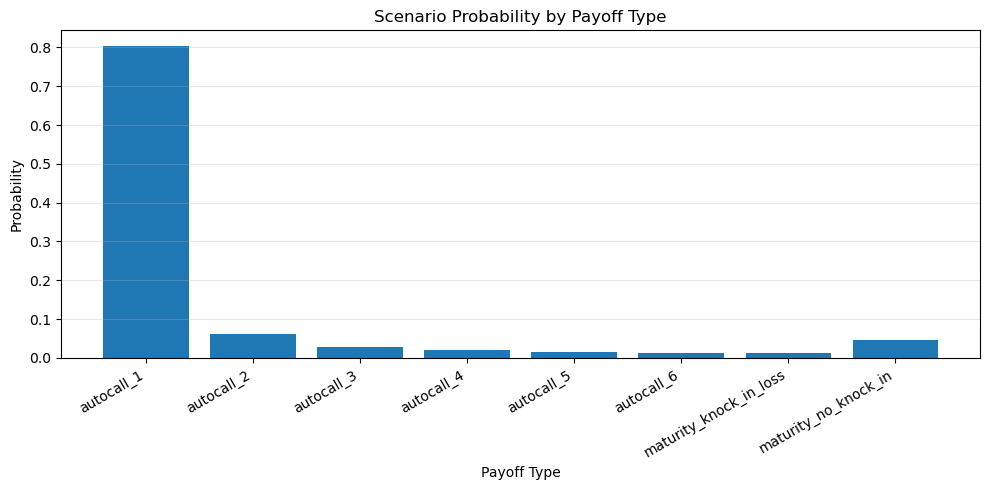

Saved figure to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\figures\section8_payoff_type_probability.png


In [18]:
# ============================================================
# 8-9-1. Payoff Type Probability
# ============================================================

plt.figure(figsize=(10, 5))
plt.bar(
    best_by_payoff_type["payoff_type"],
    best_by_payoff_type["probability"]
)
plt.title("Scenario Probability by Payoff Type")
plt.xlabel("Payoff Type")
plt.ylabel("Probability")
plt.xticks(rotation=30, ha="right")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()

fig_path = FIGURE_DIR / "section8_payoff_type_probability.png"
plt.savefig(fig_path, dpi=300)
plt.show()

print("Saved figure to:", fig_path)

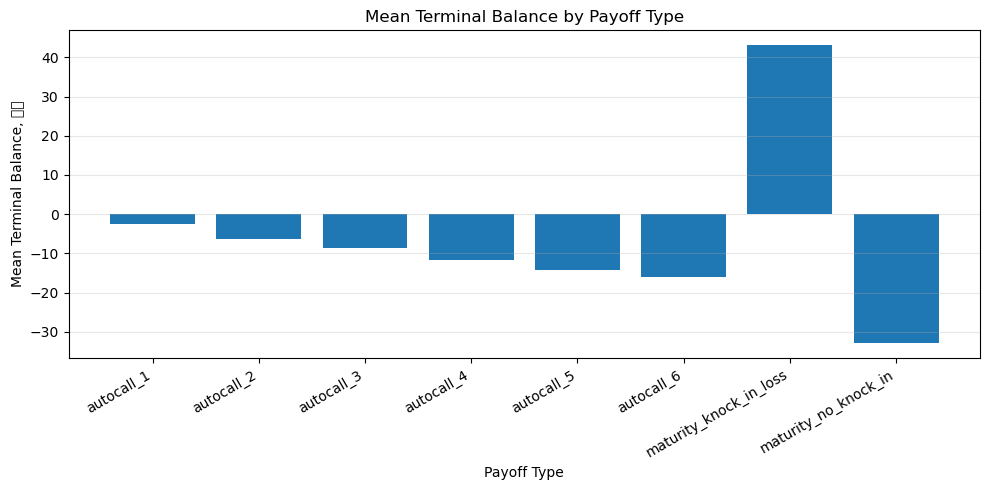

Saved figure to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\figures\section8_terminal_balance_by_payoff_type.png


In [19]:
# ============================================================
# 8-9-2. Terminal Balance by Payoff Type
# ============================================================

plt.figure(figsize=(10, 5))
plt.bar(
    best_by_payoff_type["payoff_type"],
    best_by_payoff_type["mean_terminal_balance"] / 1e8
)
plt.title("Mean Terminal Balance by Payoff Type")
plt.xlabel("Payoff Type")
plt.ylabel("Mean Terminal Balance, 억원")
plt.xticks(rotation=30, ha="right")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()

fig_path = FIGURE_DIR / "section8_terminal_balance_by_payoff_type.png"
plt.savefig(fig_path, dpi=300)
plt.show()

print("Saved figure to:", fig_path)

In [20]:
# ============================================================
# 8-10. Key Metrics for Recommended Strategy
# ============================================================

key_metrics = {
    "recommended_experiment_id": recommended_id,
    
    "principal_book_ratio": recommended["principal_book_ratio"],
    "hedge_book_ratio": recommended["hedge_book_ratio"],
    "static_ratio": recommended["static_ratio"],
    "dynamic_ratio": recommended["dynamic_ratio"],
    
    "principal_book_amount_100m": recommended["principal_book_amount"] / 1e8,
    "hedge_book_amount_100m": recommended["hedge_book_amount"] / 1e8,
    "static_budget_100m": recommended["static_budget"] / 1e8,
    "dynamic_budget_100m": recommended["dynamic_budget"] / 1e8,
    
    "mean_terminal_balance_100m": recommended["mean_terminal_balance"] / 1e8,
    "std_terminal_balance_100m": recommended["std_terminal_balance"] / 1e8,
    "p05_terminal_balance_100m": recommended["p05_terminal_balance"] / 1e8,
    "p50_terminal_balance_100m": recommended["p50_terminal_balance"] / 1e8,
    "min_terminal_balance_100m": recommended["min_terminal_balance"] / 1e8,
    
    "prob_negative_balance": recommended["prob_negative_balance"],
    "prob_below_initial_notional": recommended["prob_below_initial_notional"],
    "risk_adjusted_score_100m": recommended["risk_adjusted_score"] / 1e8,
}

key_metrics_df = pd.DataFrame([key_metrics])
key_metrics_df

,recommended_experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,principal_book_amount_100m,hedge_book_amount_100m,static_budget_100m,dynamic_budget_100m,mean_terminal_balance_100m,std_terminal_balance_100m,p05_terminal_balance_100m,p50_terminal_balance_100m,min_terminal_balance_100m,prob_negative_balance,prob_below_initial_notional,risk_adjusted_score_100m
0,10,0.300000,0.700000,1.000000,0.000000,30.000000,70.000000,70.000000,0.000000,-4.307220,8.914989,-15.994089,-2.875319,-50.689095,0.986700,1.000000,-8.764714


In [21]:
# ============================================================
# 8-11. Report Text Draft
# ============================================================

principal_ratio = recommended["principal_book_ratio"]
hedge_ratio = recommended["hedge_book_ratio"]
static_ratio = recommended["static_ratio"]
dynamic_ratio = recommended["dynamic_ratio"]

mean_tb = recommended["mean_terminal_balance"] / 1e8
p05_tb = recommended["p05_terminal_balance"] / 1e8
p50_tb = recommended["p50_terminal_balance"] / 1e8
std_tb = recommended["std_terminal_balance"] / 1e8
prob_below_notional = recommended["prob_below_initial_notional"]

report_text = f"""
본 프로젝트는 KOSPI200을 기초자산으로 하는 낙인형 스텝다운 ELS에 대해
상수변동성 Black-Scholes framework 하에서 Monte Carlo simulation, FDM delta estimation,
정적헤지 및 동적헤지 운용을 결합하여 최적 헤지비율을 분석하였다.

최종 성과평가 기준은 path별 terminal balance로 설정하였다. 이는 원금북 운용성과,
정적헤지 성과, 동적헤지 성과를 합산한 뒤 투자자에게 지급해야 하는 ELS payoff를 차감한
발행자 관점의 최종 잔고이다.

분석 결과, tail risk를 고려한 5% terminal balance 기준 최적 조합은
원금북 비중 {principal_ratio:.0%}, 헤지북 비중 {hedge_ratio:.0%}이다.
헤지북 내에서는 정적헤지 비중 {static_ratio:.0%}, 동적헤지 비중 {dynamic_ratio:.0%}가
가장 우수한 조합으로 나타났다.

해당 조합의 평균 terminal balance는 약 {mean_tb:,.2f}억원,
중앙값은 약 {p50_tb:,.2f}억원, 5% terminal balance는 약 {p05_tb:,.2f}억원으로 나타났다.
terminal balance의 표준편차는 약 {std_tb:,.2f}억원이며,
초기 발행금액 100억원을 하회할 확률은 {prob_below_notional:.2%}로 추정되었다.

따라서 단순 평균 잔고뿐 아니라 하방위험 방어력을 함께 고려할 경우,
본 조합이 주어진 헤지북 제약 내에서 가장 안정적인 헤지운용 조합으로 판단된다.
"""

print(report_text)


본 프로젝트는 KOSPI200을 기초자산으로 하는 낙인형 스텝다운 ELS에 대해
상수변동성 Black-Scholes framework 하에서 Monte Carlo simulation, FDM delta estimation,
정적헤지 및 동적헤지 운용을 결합하여 최적 헤지비율을 분석하였다.

최종 성과평가 기준은 path별 terminal balance로 설정하였다. 이는 원금북 운용성과,
정적헤지 성과, 동적헤지 성과를 합산한 뒤 투자자에게 지급해야 하는 ELS payoff를 차감한
발행자 관점의 최종 잔고이다.

분석 결과, tail risk를 고려한 5% terminal balance 기준 최적 조합은
원금북 비중 30%, 헤지북 비중 70%이다.
헤지북 내에서는 정적헤지 비중 100%, 동적헤지 비중 0%가
가장 우수한 조합으로 나타났다.

해당 조합의 평균 terminal balance는 약 -4.31억원,
중앙값은 약 -2.88억원, 5% terminal balance는 약 -15.99억원으로 나타났다.
terminal balance의 표준편차는 약 8.91억원이며,
초기 발행금액 100억원을 하회할 확률은 100.00%로 추정되었다.

따라서 단순 평균 잔고뿐 아니라 하방위험 방어력을 함께 고려할 경우,
본 조합이 주어진 헤지북 제약 내에서 가장 안정적인 헤지운용 조합으로 판단된다.



In [22]:
# ============================================================
# 8-12. Save Final Analysis Outputs
# ============================================================

final_key_metrics_path = OUTPUT_DIR / "final_key_metrics.csv"
final_report_text_path = OUTPUT_DIR / "final_report_text.txt"
final_top_by_mean_path = OUTPUT_DIR / "final_top10_by_mean.csv"
final_top_by_p05_path = OUTPUT_DIR / "final_top10_by_p05.csv"
final_top_by_score_path = OUTPUT_DIR / "final_top10_by_score.csv"
component_summary_path = OUTPUT_DIR / "final_component_summary.csv"

key_metrics_df.to_csv(
    final_key_metrics_path,
    index=False,
    encoding="utf-8-sig"
)

top_by_mean.to_csv(
    final_top_by_mean_path,
    index=False,
    encoding="utf-8-sig"
)

top_by_p05.to_csv(
    final_top_by_p05_path,
    index=False,
    encoding="utf-8-sig"
)

top_by_score.to_csv(
    final_top_by_score_path,
    index=False,
    encoding="utf-8-sig"
)

component_summary.to_csv(
    component_summary_path,
    encoding="utf-8-sig"
)

with open(final_report_text_path, "w", encoding="utf-8") as f:
    f.write(report_text)

print("Saved final key metrics to:", final_key_metrics_path)
print("Saved final report text to:", final_report_text_path)
print("Saved top ranking tables")
print("Saved component summary to:", component_summary_path)

Saved final key metrics to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\final_key_metrics.csv
Saved final report text to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\final_report_text.txt
Saved top ranking tables
Saved component summary to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\final_component_summary.csv
